# 03 · Can a small model tell which IPOs will list above their issue price?

Notebook 02 found that subscription demand strongly predicts the listing-day gain. This notebook asks whether a small, honest model does any better than subscription alone at one practical question: **will this IPO open above its issue price?**

**Design, fixed before the test period was scored.**
- **One logistic regression per segment.** Mainboard and SME are never pooled.
- **Time split.** The model is fitted on IPOs listed up to the end of 2023 and tested on IPOs listed from January 2024 to the snapshot. Every step (imputation, scaling, the regression) is fitted on the training years only.
- **Inputs known before listing:** final subscription by investor category, issue size and issue price.
- **Choices are made on the training years alone,** using forward-moving validation years (§1). The test period is scored once, at the end.
- **Baselines it has to beat:** always predicting the training base rate; the rule "total subscription above 10×"; and subscription on its own, which ranks IPOs as well as any "above N×" rule for every N.

**Target.** `listing_gain_pct > 0`: the listing-day open is above the issue price. A listing exactly at the issue price counts as not positive. A second version uses `> 10` (§4).

**Scores.**
- *ROC AUC*: the chance that a randomly chosen positive listing gets a higher score than a randomly chosen non-positive one (0.5 is no better than chance).
- *Brier score*: the mean squared error of the predicted probability (lower is better).
- *Calibration*: whether IPOs given 80% actually list positive about 80% of the time.
- Intervals are 95% bootstrap intervals (10,000 resamples, fixed seed; `src/stats.py`). Model and baseline are compared on the same resamples.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pipeline.py').exists())
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from src.config import SEGMENTS
from src.data import at_listing_ceiling, load_mart
from src.plotting import MUTED, SEGMENT_COLORS, SEGMENT_LABELS, apply_style, percent_axis, save_fig
from src.stats import (SEED, Estimate, bootstrap_auc, bootstrap_auc_diff, bootstrap_brier_diff, bootstrap_median,
                       bootstrap_median_diff, roc_auc)

apply_style()
pd.set_option('display.float_format', '{:,.3f}'.format)
pd.set_option('display.max_colwidth', 90)

df = load_mart()
SNAPSHOT = df['snapshot_date'].iloc[0]

## 0 · Sample and split

- **Same sample as notebook 02:** IPOs with a listing-day price and subscription figures, SME from 2018.
- **Train:** listed up to 31 Dec 2023. **Test:** listed from 1 Jan 2024.
- Subscription multiples and issue size are heavily skewed, so they enter on a log2 scale: one unit is a doubling.

In [2]:
SME_FROM = pd.Timestamp('2018-01-01')
TEST_FROM = pd.Timestamp('2024-01-01')

in_sample = (df['has_subscription_figures'] & df['has_listing_price']
             & ((df['segment'] == 'MAINBOARD') | (df['listing_dt'] >= SME_FROM)))
sample = df[in_sample].copy()
for category in ['total', 'qib', 'nii', 'retail']:
    # One SME issue has a QIB multiple of exactly 0; 0.01x keeps it on the log scale at the bottom
    sample[f'log2_{category}'] = np.log2(sample[f'subscription_{category}_x'].clip(lower=0.01))
sample['log2_issue_size'] = np.log2(sample['issue_size_cr'])
sample['log2_issue_price'] = np.log2(sample['issue_price'])
sample['listing_month'] = sample['listing_dt'].dt.month.astype(str)
sample['listing_year'] = sample['listing_year'].astype(int)
sample['period'] = pd.Categorical(np.where(sample['listing_dt'] < TEST_FROM, 'train', 'test'),
                                  categories=['train', 'test'], ordered=True)
sample['at_ceiling'] = at_listing_ceiling(sample)

train = {s: sample[(sample['segment'] == s) & (sample['period'] == 'train')] for s in SEGMENTS}
test = {s: sample[(sample['segment'] == s) & (sample['period'] == 'test')] for s in SEGMENTS}


def target(frame, above=0):
    return (frame['listing_gain_pct'] > above).astype(int)


sample.groupby(['segment', 'period'], observed=True).agg(
    ipos=('ticker', 'size'),
    first_listing=('listing_dt', lambda v: v.min().date()),
    last_listing=('listing_dt', lambda v: v.max().date()),
    share_above_0=('listing_gain_pct', lambda v: (v > 0).mean()),
    share_exactly_0=('listing_gain_pct', lambda v: (v == 0).mean()),
    share_above_10=('listing_gain_pct', lambda v: (v > 10).mean()),
    share_with_qib_figure=('subscription_qib_x', lambda v: v.notna().mean()),
    at_listing_ceiling=('at_ceiling', 'sum'),
).T

segment                 MAINBOARD                     SME            
period                      train        test       train        test
ipos                          261         187         293         296
first_listing          2016-02-08  2024-01-16  2018-01-10  2024-01-01
last_listing           2023-12-29  2025-12-30  2023-12-29  2026-01-02
share_above_0               0.701       0.727       0.778       0.777
share_exactly_0             0.057       0.086       0.102       0.061
share_above_10              0.467       0.513       0.413       0.595
share_with_qib_figure       0.996       1.000       0.239       0.814
at_listing_ceiling              0           0           6          43

**Reading.**
- **Sizes:** 261 mainboard and 293 SME IPOs to train on; 187 and 296 to test on. Every test-period score below rests on a couple of hundred IPOs, so intervals are wide.
- **The target's base rate barely moved:** 70% of mainboard IPOs listed positive in the training years and 73% in the test period; for SME, 78% in both. A model can't win by predicting "positive" more often.
- **Everything else did.**
  - Listing gains above 10% became more common for SME (41% to 60%).
  - 43 test-period SME listings opened at the +90% cap.
  - QIB figures cover 24% of SME training IPOs but 81% of test IPOs, which is why SME has no QIB input.
- **Flat listings** (open exactly at the issue price) are 6–10% of each group and count as not positive.

### Inputs

| Input | Mainboard | SME |
|---|---|---|
| Total, NII and retail subscription (log2) | ✓ | ✓ |
| QIB subscription (log2) | ✓ | — |
| Issue size and issue price (log2) | ✓ | ✓ |

- **No QIB input for SME.** Only 24% of SME training IPOs have a QIB figure, against 81% in the test period, because Chittorgarh reports SME QIB demand mainly from 2023. A QIB input, or the `has_qib_category` flag, would mostly tell the model which period an IPO is from.
- **No `has_qib_category` for mainboard either:** every mainboard IPO in the sample has a QIB category, so it carries no information.
- **Missing values** (a handful of QIB and retail figures) are filled with the training median.
- **Listing month** was in the original plan. It is tested in §1 and left out.

In [3]:
SUBSCRIPTION = {'MAINBOARD': ['log2_total', 'log2_qib', 'log2_nii', 'log2_retail'],
                'SME': ['log2_total', 'log2_nii', 'log2_retail']}
ISSUE = ['log2_issue_size', 'log2_issue_price']
MONTH = ['listing_month']


def make_model(numeric, categorical=(), C=1.0):
    """Impute and scale numeric inputs, one-hot encode categorical ones, then a logistic regression"""
    parts = [('numeric', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), list(numeric))]
    if categorical:
        parts.append(('categorical', OneHotEncoder(handle_unknown='ignore'), list(categorical)))
    return Pipeline([('prepare', ColumnTransformer(parts)),
                     ('classify', LogisticRegression(C=C, max_iter=1000))])

## 1 · Choosing the inputs, on the training years only

Each candidate is fitted on the years before a validation year and scored on that year, for 2021, 2022 and 2023 in turn, so every validation IPO is predicted by a model that has only seen earlier listings. Scores pool the three validation years. The test period is not touched.

In [4]:
VALIDATION_YEARS = [2021, 2022, 2023]


def candidates(segment):
    return {
        'Total subscription only': (['log2_total'], []),
        'Subscription by category': (SUBSCRIPTION[segment], []),
        '+ issue size and price': (SUBSCRIPTION[segment] + ISSUE, []),
        '+ listing month': (SUBSCRIPTION[segment] + ISSUE, MONTH),
    }


def forward_validation(frame, numeric, categorical, above=0, C=1.0):
    probs, labels, base = [], [], []
    for year in VALIDATION_YEARS:
        fit, val = frame[frame['listing_year'] < year], frame[frame['listing_year'] == year]
        model = make_model(numeric, categorical, C).fit(fit, target(fit, above))
        probs.append(model.predict_proba(val)[:, 1])
        labels.append(target(val, above).to_numpy())
        base.append(np.full(len(val), target(fit, above).mean()))
    p, y, b = np.concatenate(probs), np.concatenate(labels), np.concatenate(base)
    return {'n': len(y), 'auc': roc_auc(y, p), 'brier': np.mean((p - y) ** 2), 'base_rate_brier': np.mean((b - y) ** 2)}


rows = []
for above in (0, 10):
    for segment in SEGMENTS:
        for name, (numeric, categorical) in candidates(segment).items():
            scores = forward_validation(train[segment], numeric, categorical, above)
            rows.append({'target': f'gain > {above}%', 'segment': SEGMENT_LABELS[segment], 'inputs': name, **scores})
validation = pd.DataFrame(rows)
validation.set_index(['target', 'segment', 'inputs'])

n   auc  brier  \
target     segment   inputs                                       
gain > 0%  Mainboard Total subscription only   155 0.820  0.152   
                     Subscription by category  155 0.810  0.159   
                     + issue size and price    155 0.803  0.161   
                     + listing month           155 0.785  0.167   
           SME       Total subscription only   193 0.675  0.144   
                     Subscription by category  193 0.731  0.137   
                     + issue size and price    193 0.728  0.137   
                     + listing month           193 0.700  0.151   
gain > 10% Mainboard Total subscription only   155 0.922  0.117   
                     Subscription by category  155 0.910  0.129   
                     + issue size and price    155 0.905  0.131   
                     + listing month           155 0.883  0.142   
           SME       Total subscription only   193 0.832  0.168   
                     Subscription by category  193 0.861  0.154   
                     + issue size and price    193 0.847  0.163   
                     + listing month           193 0.837  0.172   

                                               base_rate_brier  
target     segment   inputs                                     
gain > 0%  Mainboard Total subscription only             0.197  
                     Subscription by category            0.197  
                     + issue size and price              0.197  
                     + listing month                     0.197  
           SME       Total subscription only             0.160  
                     Subscription by category            0.160  
                     + issue size and price              0.160  
                     + listing month                     0.160  
gain > 10% Mainboard Total subscription only             0.261  
                     Subscription by category            0.261  
                     + issue size and price              0.261  
                     + listing month                     0.261  
           SME       Total subscription only             0.353  
                     Subscription by category            0.353  
                     + issue size and price              0.353  
                     + listing month                     0.353

In [5]:
# Regularisation strength: the chosen inputs at C = 0.1, 1 (the default, used) and 10
pd.DataFrame([
    {'target': f'gain > {above}%', 'segment': SEGMENT_LABELS[segment], 'C': C,
     **forward_validation(train[segment], SUBSCRIPTION[segment] + ISSUE, [], above, C)}
    for above in (0, 10) for segment in SEGMENTS for C in (0.1, 1.0, 10.0)
]).pivot(index=['target', 'segment'], columns='C', values='auc').add_prefix('AUC at C=')

C                     AUC at C=0.1  AUC at C=1.0  AUC at C=10.0
target     segment                                             
gain > 0%  Mainboard         0.807         0.803          0.802
           SME               0.714         0.728          0.731
gain > 10% Mainboard         0.910         0.905          0.905
           SME               0.840         0.847          0.854

**Reading.**
- **Mainboard: nothing beats total subscription on its own.** Adding the categories, then issue size and price, then listing month each lowers the validation AUC (0.82 → 0.81 → 0.80 → 0.79) and raises the Brier score.
- **SME: the categories help.** Total, NII and retail subscription together reach AUC 0.73 against 0.68 for total alone, and Brier 0.137 against 0.144. Issue size and price add nothing (0.73).
- **Listing month makes both segments worse**, by 0.02–0.03 AUC for a positive listing. With 12 month dummies on a few hundred IPOs, it fits noise. It is left out.
- **Regularisation barely matters:** AUC changes by at most 0.02 between C = 0.1 and C = 10, so the default C = 1 is kept.
- **Chosen:** subscription by category plus issue size and price, for both segments (the plan without listing month).
  - For mainboard, validation already suggests this is no better than subscription alone.
  - It is kept rather than swapped for total subscription, so that the test scores the planned model, not one picked because it scored best. Subscription alone is reported next to it anyway.
- All candidates beat the base rate comfortably: validation Brier 0.14–0.17 against 0.20 (mainboard) and 0.16 (SME).

In [6]:
FEATURES = {s: SUBSCRIPTION[s] + ISSUE for s in SEGMENTS}
FEATURES

{'MAINBOARD': ['log2_total',
  'log2_qib',
  'log2_nii',
  'log2_retail',
  'log2_issue_size',
  'log2_issue_price'],
 'SME': ['log2_total',
  'log2_nii',
  'log2_retail',
  'log2_issue_size',
  'log2_issue_price']}

## 2 · Test period: does the model beat the baselines?

Everything below is fitted on the training years once and scored on IPOs listed from 2024.

- **Training base rate:** predicts the share of positive listings in the training years for every IPO. Its AUC is 0.5 by construction.
- **Rule "total > 10×":** a yes/no forecast, so it has an accuracy and an AUC but no meaningful Brier score.
- **Subscription alone:** a logistic regression on log2 total subscription only. It ranks IPOs exactly as the raw subscription multiple does.
- Accuracy uses a probability above 0.5 as "positive". *Precision* is the share of IPOs forecast positive that were.
  About three in four IPOs list positive, so a 0.5 cut-off flags nearly everything and accuracy barely separates the forecasts. AUC (ranking) and Brier (probabilities) are the main scores.

In [7]:
FORECASTS = {'p_base_rate': 'Training base rate', 'rule_10x': 'Rule: total > 10×',
             'p_subscription': 'Subscription alone', 'p_model': 'Model'}


def fit_and_predict(above=0):
    results = {}
    for s in SEGMENTS:
        y_train = target(train[s], above)
        model = make_model(FEATURES[s]).fit(train[s], y_train)
        subscription_only = make_model(['log2_total']).fit(train[s], y_train)
        results[s] = {
            'model': model,
            'y': target(test[s], above).to_numpy(),
            'p_base_rate': np.full(len(test[s]), y_train.mean()),
            'rule_10x': (test[s]['subscription_total_x'] > 10).astype(float).to_numpy(),
            'p_subscription': subscription_only.predict_proba(test[s])[:, 1],
            'p_model': model.predict_proba(test[s])[:, 1],
        }
    return results


def score_table(results):
    rows = []
    for s, r in results.items():
        y = r['y']
        for key, name in FORECASTS.items():
            score = r[key]
            forecast_positive = score > 0.5
            auc = bootstrap_auc(y, score)
            rows.append({
                'segment': SEGMENT_LABELS[s], 'forecast': name, 'n': len(y), 'test_base_rate': y.mean(),
                'auc': auc.estimate, 'auc_ci': f'[{auc.ci_low:.2f}, {auc.ci_high:.2f}]',
                'brier': np.nan if key == 'rule_10x' else np.mean((score - y) ** 2),
                'accuracy': (forecast_positive == y).mean(),
                'share_forecast_positive': forecast_positive.mean(),
                'precision': y[forecast_positive].mean() if forecast_positive.any() else np.nan,
            })
    return pd.DataFrame(rows).set_index(['segment', 'forecast'])


def comparison_table(results):
    rows = []
    for s, r in results.items():
        y = r['y']
        tests = [
            ('Model − subscription alone', 'AUC', bootstrap_auc_diff(y, r['p_model'], r['p_subscription'])),
            ('Model − subscription alone', 'Brier', bootstrap_brier_diff(y, r['p_model'], r['p_subscription'])),
            ('Model − rule > 10×', 'AUC', bootstrap_auc_diff(y, r['p_model'], r['rule_10x'])),
            ('Model − training base rate', 'Brier', bootstrap_brier_diff(y, r['p_model'], r['p_base_rate'])),
            ('Subscription alone − training base rate', 'Brier',
             bootstrap_brier_diff(y, r['p_subscription'], r['p_base_rate'])),
        ]
        for comparison, measure, estimate in tests:
            rows.append({'segment': SEGMENT_LABELS[s], 'comparison': comparison, 'measure': measure,
                         'difference': estimate.estimate, 'ci_low': estimate.ci_low, 'ci_high': estimate.ci_high,
                         'n': estimate.n})
    return pd.DataFrame(rows).set_index(['segment', 'comparison', 'measure'])


results = fit_and_predict(above=0)
score_table(results)

n  test_base_rate   auc        auc_ci  brier  \
segment   forecast                                                             
Mainboard Training base rate  187           0.727 0.500  [0.50, 0.50]  0.199   
          Rule: total > 10×   187           0.727 0.729  [0.65, 0.80]    NaN   
          Subscription alone  187           0.727 0.831  [0.77, 0.89]  0.155   
          Model               187           0.727 0.835  [0.78, 0.89]  0.160   
SME       Training base rate  296           0.777 0.500  [0.50, 0.50]  0.173   
          Rule: total > 10×   296           0.777 0.702  [0.64, 0.77]    NaN   
          Subscription alone  296           0.777 0.798  [0.74, 0.85]  0.155   
          Model               296           0.777 0.820  [0.76, 0.87]  0.149   

                              accuracy  share_forecast_positive  precision  
segment   forecast                                                          
Mainboard Training base rate     0.727                    1.000      0.727  
          Rule: total > 10×      0.775                    0.706      0.856  
          Subscription alone     0.765                    0.802      0.807  
          Model                  0.754                    0.813      0.796  
SME       Training base rate     0.777                    1.000      0.777  
          Rule: total > 10×      0.780                    0.753      0.870  
          Subscription alone     0.777                    1.000      0.777  
          Model                  0.780                    0.997      0.780

Differences on the same bootstrap resamples. For AUC, positive favours the first forecast; for Brier, **negative** favours the first forecast.

In [8]:
comparison_table(results)

difference  ci_low  \
segment   comparison                              measure                       
Mainboard Model − subscription alone              AUC           0.004  -0.012   
                                                  Brier         0.005  -0.001   
          Model − rule > 10×                      AUC           0.106   0.058   
          Model − training base rate              Brier        -0.039  -0.067   
          Subscription alone − training base rate Brier        -0.044  -0.071   
SME       Model − subscription alone              AUC           0.022  -0.008   
                                                  Brier        -0.006  -0.012   
          Model − rule > 10×                      AUC           0.118   0.065   
          Model − training base rate              Brier        -0.024  -0.034   
          Subscription alone − training base rate Brier        -0.018  -0.025   

                                                           ci_high    n  
segment   comparison                              measure                
Mainboard Model − subscription alone              AUC        0.020  187  
                                                  Brier      0.010  187  
          Model − rule > 10×                      AUC        0.155  187  
          Model − training base rate              Brier     -0.011  187  
          Subscription alone − training base rate Brier     -0.016  187  
SME       Model − subscription alone              AUC        0.052  296  
                                                  Brier     -0.001  296  
          Model − rule > 10×                      AUC        0.171  296  
          Model − training base rate              Brier     -0.014  296  
          Subscription alone − training base rate Brier     -0.011  296

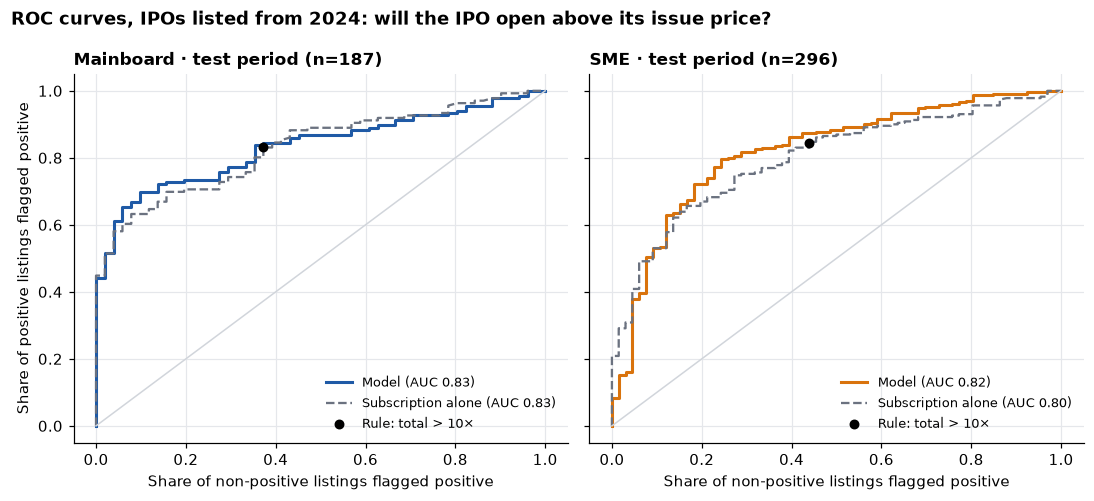

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
for ax, s in zip(axes, SEGMENTS):
    r = results[s]
    for key, style in [('p_model', dict(color=SEGMENT_COLORS[s], lw=2)),
                       ('p_subscription', dict(color=MUTED, lw=1.5, ls='--'))]:
        fpr, tpr, _ = roc_curve(r['y'], r[key])
        ax.plot(fpr, tpr, label=f"{FORECASTS[key]} (AUC {roc_auc(r['y'], r[key]):.2f})", **style)
    y, rule = r['y'], r['rule_10x'] == 1
    ax.scatter([rule[y == 0].mean()], [rule[y == 1].mean()], color='black', zorder=3, s=30,
               label='Rule: total > 10×')
    ax.plot([0, 1], [0, 1], color='#d1d5db', lw=1)
    ax.set_title(f'{SEGMENT_LABELS[s]} · test period (n={len(y)})')
    ax.set_xlabel('Share of non-positive listings flagged positive')
    ax.legend(loc='lower right', fontsize=8.5)
axes[0].set_ylabel('Share of positive listings flagged positive')
fig.suptitle('ROC curves, IPOs listed from 2024: will the IPO open above its issue price?',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '03_roc_test_period')
plt.show()

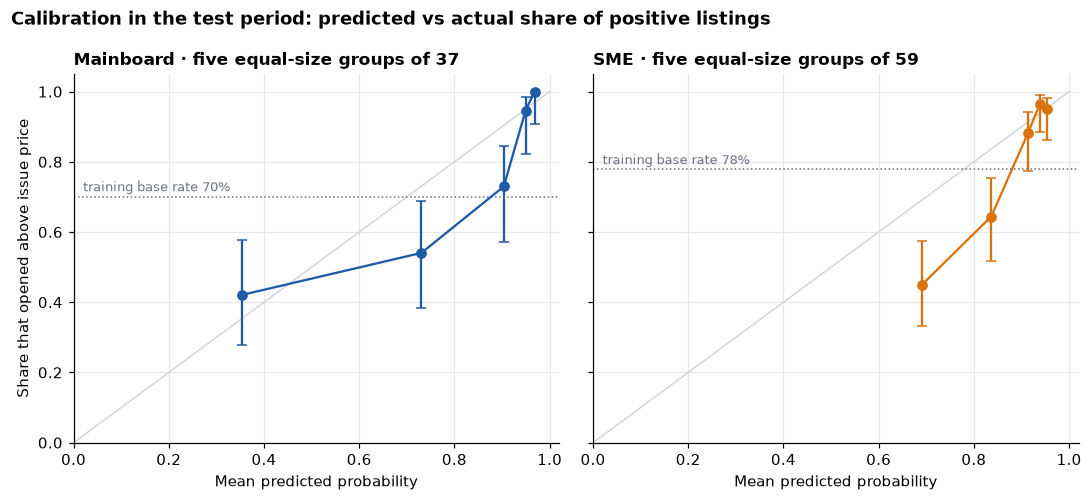

forecast  observed   n   low  high
segment   group                                    
MAINBOARD 0         0.354     0.421  38 0.279 0.578
          1         0.731     0.541  37 0.384 0.690
          2         0.904     0.730  37 0.570 0.846
          3         0.949     0.946  37 0.823 0.985
          4         0.968     1.000  38 0.908 1.000
SME       0         0.691     0.450  60 0.331 0.575
          1         0.836     0.644  59 0.517 0.754
          2         0.913     0.881  59 0.775 0.941
          3         0.939     0.966  59 0.885 0.991
          4         0.954     0.949  59 0.861 0.983

In [10]:
def calibration_bins(y, p, bins=5):
    """Equal-count bins of predicted probability: mean forecast, observed share and a Wilson 95% interval"""
    frame = pd.DataFrame({'y': y, 'p': p})
    frame['bin'] = pd.qcut(frame['p'].rank(method='first'), bins, labels=False)
    table = frame.groupby('bin').agg(forecast=('p', 'mean'), observed=('y', 'mean'), n=('y', 'size'))
    z = 1.96
    centre = (table['observed'] + z ** 2 / (2 * table['n'])) / (1 + z ** 2 / table['n'])
    half = z * np.sqrt(table['observed'] * (1 - table['observed']) / table['n'] + z ** 2 / (4 * table['n'] ** 2)) / (1 + z ** 2 / table['n'])
    # A group where every IPO listed positive has an upper limit of 1 up to float error, so clip to the observed share
    return table.assign(low=np.minimum(centre - half, table['observed']), high=np.maximum(centre + half, table['observed']))


calibration = {s: calibration_bins(results[s]['y'], results[s]['p_model']) for s in SEGMENTS}
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
for ax, s in zip(axes, SEGMENTS):
    table = calibration[s]
    ax.plot([0, 1], [0, 1], color='#d1d5db', lw=1)
    ax.errorbar(table['forecast'], table['observed'],
                yerr=[table['observed'] - table['low'], table['high'] - table['observed']],
                fmt='o-', color=SEGMENT_COLORS[s], capsize=3)
    base = results[s]['p_base_rate'][0]
    ax.axhline(base, color=MUTED, ls=':', lw=1)
    ax.text(0.02, base + 0.015, f'training base rate {base:.0%}', color=MUTED, fontsize=8.5)
    ax.set_xlim(0, 1.02)
    ax.set_ylim(0, 1.05)
    ax.set_title(f'{SEGMENT_LABELS[s]} · five equal-size groups of {len(results[s]["y"]) // 5}')
    ax.set_xlabel('Mean predicted probability')
axes[0].set_ylabel('Share that opened above issue price')
fig.suptitle('Calibration in the test period: predicted vs actual share of positive listings',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '03_calibration_test_period')
plt.show()
pd.concat(calibration, names=['segment', 'group'])

**Did the meaning of a subscription multiple change?** Median subscription and the share of positive listings at the same subscription level, training years vs test period.

In [11]:
BANDS = [0, 3, 10, 30, 100, 300, np.inf]
band_labels = ['≤ 3×', '3–10×', '10–30×', '30–100×', '100–300×', '> 300×']
drift = sample.assign(band=pd.cut(sample['subscription_total_x'], BANDS, labels=band_labels))
for s in SEGMENTS:
    r = results[s]
    print(f"{SEGMENT_LABELS[s]}: share listing positive {r['y'].mean():.3f}; mean forecast, model "
          f"{r['p_model'].mean():.3f}, subscription alone {r['p_subscription'].mean():.3f}")
print('\nMedian total subscription:')
print(drift.groupby(['segment', 'period'], observed=True)['subscription_total_x'].median().unstack('period').to_string())
drift.groupby(['segment', 'band', 'period'], observed=True)['listing_gain_pct'].agg(
    share_positive=lambda v: (v > 0).mean(), ipos='size').unstack('period')

Mainboard: share listing positive 0.727; mean forecast, model 0.780, subscription alone 0.775
SME: share listing positive 0.777; mean forecast, model 0.866, subscription alone 0.845

Median total subscription:
period     train   test
segment                
MAINBOARD 17.210 39.170
SME        8.930 88.465


share_positive        ipos     
period                      train  test train test
segment   band                                    
MAINBOARD ≤ 3×              0.362 0.364    69   33
          3–10×             0.600 0.500    45   22
          10–30×            0.595 0.645    37   31
          30–100×           0.986 0.875    72   64
          100–300×          1.000 1.000    36   35
          > 300×            1.000 1.000     2    2
SME       ≤ 3×              0.680 0.500   100   36
          3–10×             0.745 0.486    51   37
          10–30×            0.744 0.688    39   32
          30–100×           0.833 0.796    48   49
          100–300×          0.949 0.896    39   77
          > 300×            1.000 0.985    16   65

**Reading.**
- **The model clearly beats two of the three baselines.**
  - *Training base rate:* Brier 0.160 vs 0.199 for mainboard (difference −0.039 [−0.067, −0.011]); 0.149 vs 0.173 for SME (−0.024 [−0.034, −0.014]).
  - *Rule "> 10×", at ranking:* AUC +0.11 [+0.06, +0.16] for mainboard and +0.12 [+0.07, +0.17] for SME.
  - *Rule "> 10×", as a single yes/no call:* the rule is at least as accurate as the model (0.78 vs 0.75 for mainboard; 0.78 vs 0.78 for SME). A 10× cut-off happens to sit in a useful place in 2024–25. It wouldn't have in the training years, when the median SME IPO was subscribed under 9× and still 78% listed positive.
- **Mainboard: it doesn't beat subscription alone.**
  - *AUC:* 0.835 vs 0.831, a difference of +0.004 [−0.012, +0.020].
  - *Brier:* slightly worse, +0.005 [−0.001, +0.010].
  - The ROC curves lie on top of each other.
- **SME: a small gain in probabilities, not clearly in ranking.**
  - *AUC:* 0.820 vs 0.798, a difference of +0.022 [−0.008, +0.052].
  - *Brier:* 0.149 vs 0.155, a difference of −0.006 [−0.012, −0.001]. That is just clear of zero.
  - This matches validation: for SME, the mix of NII and retail demand adds something that total subscription misses.
- **Rankings carried into 2024–25; probabilities didn't.**
  - Both forecasts are too optimistic. The model's average forecast is 78% for mainboard IPOs (73% listed positive) and 87% for SME (78% did).
  - The error sits in the lower and middle groups:
    - *Mainboard:* IPOs given 73% listed positive 54% of the time, and those given 90%, 73% of the time.
    - *SME:* IPOs given 69% listed positive 45% of the time, and those given 84%, 64%.
  - The most confident fifth is well calibrated: 95–97% predicted, 95–100% positive.
- **Why.**
  - *Subscription levels jumped.* Median total subscription rose from 17× to 39× for mainboard and from 9× to 88× for SME.
  - *The same multiple lists positive less often.*
    - SME IPOs subscribed 3–10× listed positive 75% of the time in the training years and 49% in the test period.
    - Those subscribed 3× or less went from 68% to 50%.
    - Mainboard IPOs at 30–100× went from 99% to 88%.
  - A model trained on the old relationship reads a middling multiple as better news than it now is. Anyone using it on new IPOs would need to recalibrate it on recent listings first.

## 3 · What the model has learned

Coefficients are shown as **odds multipliers per doubling** of each input, holding the others fixed: 1.5 means doubling that input multiplies the odds of a positive listing by 1.5. Intervals come from refitting the pipeline on 1,000 bootstrap resamples of the training years (refits are slower than the vectorised bootstraps above).

The subscription categories move together, so the model can shift weight between them from one resample to the next. Wide or zero-straddling intervals for one category don't mean subscription as a whole doesn't matter.

In [12]:
N_REFIT = 1_000


def odds_per_doubling(model, features):
    scale = model.named_steps['prepare'].named_transformers_['numeric'].named_steps['standardscaler'].scale_
    return pd.Series(np.exp(model.named_steps['classify'].coef_[0] / scale), index=features)


LABELS = {'log2_total': 'Total subscription', 'log2_qib': 'QIB subscription', 'log2_nii': 'NII subscription',
          'log2_retail': 'Retail subscription', 'log2_issue_size': 'Issue size', 'log2_issue_price': 'Issue price'}
coefficients = []
for s in SEGMENTS:
    frame, y = train[s], target(train[s]).to_numpy()
    point = odds_per_doubling(results[s]['model'], FEATURES[s])
    rng = np.random.default_rng(SEED)
    draws = []
    for _ in range(N_REFIT):
        idx = rng.integers(0, len(frame), len(frame))
        if y[idx].min() == y[idx].max():
            continue
        draws.append(odds_per_doubling(make_model(FEATURES[s]).fit(frame.iloc[idx], y[idx]), FEATURES[s]))
    draws = pd.DataFrame(draws)
    coefficients.append(pd.DataFrame({
        'segment': SEGMENT_LABELS[s], 'input': [LABELS[f] for f in FEATURES[s]],
        'odds_per_doubling': point.values,
        'ci_low': draws.quantile(0.025).values, 'ci_high': draws.quantile(0.975).values,
    }))
coefficients = pd.concat(coefficients, ignore_index=True)
coefficients.set_index(['segment', 'input'])

odds_per_doubling  ci_low  ci_high
segment   input                                                  
Mainboard Total subscription               1.523   1.124    2.113
          QIB subscription                 1.261   0.968    1.648
          NII subscription                 1.094   0.905    1.350
          Retail subscription              0.860   0.694    1.078
          Issue size                       0.941   0.723    1.249
          Issue price                      0.919   0.677    1.236
SME       Total subscription               0.991   0.810    1.254
          NII subscription                 1.452   1.196    1.761
          Retail subscription              0.868   0.710    1.046
          Issue size                       0.986   0.696    1.339
          Issue price                      1.189   0.820    1.813

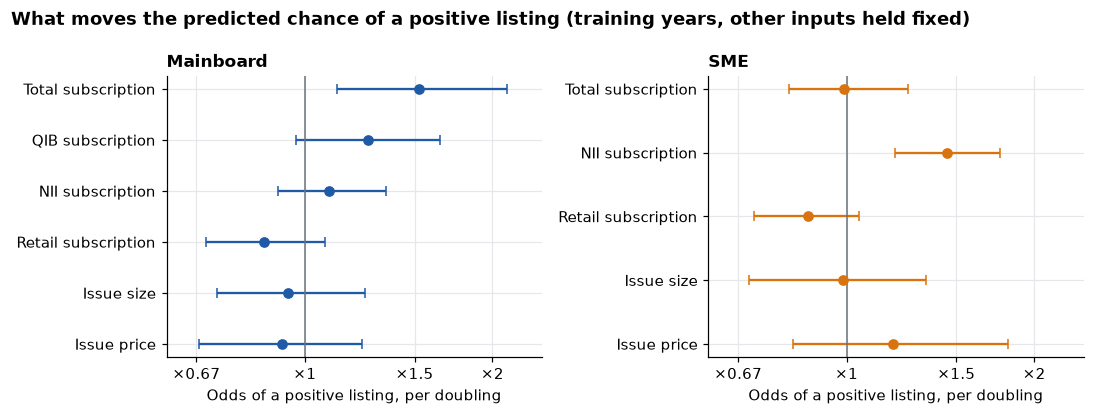

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, s in zip(axes, SEGMENTS):
    table = coefficients[coefficients['segment'] == SEGMENT_LABELS[s]].iloc[::-1]
    positions = np.arange(len(table))
    ax.errorbar(table['odds_per_doubling'], positions,
                xerr=[table['odds_per_doubling'] - table['ci_low'], table['ci_high'] - table['odds_per_doubling']],
                fmt='o', color=SEGMENT_COLORS[s], capsize=3)
    ax.axvline(1, color=MUTED, lw=1)
    ax.set_yticks(positions, table['input'])
    ax.set_xscale('log')
    ax.set_xlim(0.6, 2.4)
    ax.set_xticks([0.67, 1, 1.5, 2], ['×0.67', '×1', '×1.5', '×2'])
    ax.minorticks_off()
    ax.set_title(SEGMENT_LABELS[s])
    ax.set_xlabel('Odds of a positive listing, per doubling')
fig.suptitle('What moves the predicted chance of a positive listing (training years, other inputs held fixed)',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '03_odds_per_doubling')
plt.show()

**Reading.**
- **Mainboard: total subscription carries the model.**
  - Each doubling multiplies the odds of a positive listing by 1.52 [1.12, 2.11], with the other inputs held fixed.
  - QIB demand may add a little on top: ×1.26 [0.97, 1.65], an interval that just includes ×1.
  - The NII, retail, issue-size and issue-price intervals all include ×1.
- **SME: NII demand carries the model.**
  - Among SME IPOs with the same total and retail subscription, each doubling of NII demand multiplies the odds by 1.45 [1.20, 1.76].
  - Once NII is in, neither total subscription (×0.99 [0.81, 1.25]) nor retail demand (×0.87 [0.71, 1.05]) adds anything.
  - This fits notebook 02, where NII and retail demand were stronger listing-day signals than QIB demand for SME. It also explains why the SME model improves on total subscription while the mainboard one doesn't.
- **Issue size and issue price** don't move the odds in either segment once subscription is known.
- **Caution.** The subscription categories are strongly correlated with each other, so the model can trade weight between them. Mainboard retail's ×0.86 does not mean retail demand is bad news. It means only that once total, QIB and NII demand are known, retail demand adds nothing (its interval includes ×1).

## 4 · Sensitivity: listing gain above 10%

Same inputs, same split, target `listing_gain_pct > 10`. A listing at an SME ceiling (+20% before April 2018, +90% from July 2024) is above 10%, so the ceilings don't blur this target either.

In [14]:
results_10 = fit_and_predict(above=10)
score_table(results_10)

n  test_base_rate   auc        auc_ci  brier  \
segment   forecast                                                             
Mainboard Training base rate  187           0.513 0.500  [0.50, 0.50]  0.252   
          Rule: total > 10×   187           0.513 0.749  [0.69, 0.80]    NaN   
          Subscription alone  187           0.513 0.871  [0.82, 0.92]  0.161   
          Model               187           0.513 0.871  [0.82, 0.92]  0.165   
SME       Training base rate  296           0.595 0.500  [0.50, 0.50]  0.274   
          Rule: total > 10×   296           0.595 0.741  [0.69, 0.79]    NaN   
          Subscription alone  296           0.595 0.883  [0.84, 0.92]  0.145   
          Model               296           0.595 0.886  [0.85, 0.92]  0.138   

                              accuracy  share_forecast_positive  precision  
segment   forecast                                                          
Mainboard Training base rate     0.487                    0.000        NaN  
          Rule: total > 10×      0.754                    0.706      0.689  
          Subscription alone     0.749                    0.626      0.709  
          Model                  0.749                    0.636      0.706  
SME       Training base rate     0.405                    0.000        NaN  
          Rule: total > 10×      0.780                    0.753      0.749  
          Subscription alone     0.787                    0.672      0.784  
          Model                  0.794                    0.666      0.792

In [15]:
comparison_table(results_10)

difference  ci_low  \
segment   comparison                              measure                       
Mainboard Model − subscription alone              AUC          -0.001  -0.007   
                                                  Brier         0.004   0.001   
          Model − rule > 10×                      AUC           0.122   0.080   
          Model − training base rate              Brier        -0.087  -0.125   
          Subscription alone − training base rate Brier        -0.091  -0.128   
SME       Model − subscription alone              AUC           0.003  -0.009   
                                                  Brier        -0.007  -0.013   
          Model − rule > 10×                      AUC           0.145   0.106   
          Model − training base rate              Brier        -0.136  -0.168   
          Subscription alone − training base rate Brier        -0.129  -0.160   

                                                           ci_high    n  
segment   comparison                              measure                
Mainboard Model − subscription alone              AUC        0.006  187  
                                                  Brier      0.007  187  
          Model − rule > 10×                      AUC        0.168  187  
          Model − training base rate              Brier     -0.047  187  
          Subscription alone − training base rate Brier     -0.052  187  
SME       Model − subscription alone              AUC        0.015  296  
                                                  Brier     -0.000  296  
          Model − rule > 10×                      AUC        0.186  296  
          Model − training base rate              Brier     -0.103  296  
          Subscription alone − training base rate Brier     -0.097  296

**Reading.**
- **A gain above 10% is easier to rank than a positive listing:**
  - *Mainboard:* AUC 0.87 [0.82, 0.92].
  - *SME:* AUC 0.89 [0.85, 0.92].
- **Same pattern as for a positive listing:**
  - *Mainboard:* the model equals subscription alone at ranking (−0.001 [−0.007, +0.006]) and gives slightly worse probabilities (Brier +0.004 [+0.001, +0.007]).
  - *SME:* the model gives slightly better probabilities (Brier −0.007 [−0.013, −0.000]), and ranking is indistinguishable (+0.003 [−0.009, +0.015]).
- **The "> 10×" rule** is again well behind at ranking (AUC 0.75 and 0.74, against 0.87 and 0.89).

## 5 · A simple backtest: apply only when the model is confident

Test period, target `> 0` forecasts. "Apply" means applying to an IPO when its predicted probability is above a threshold; the thresholds were fixed before scoring. Subscription alone is shown at the same thresholds, so the model's picks can be compared with picks made on subscription only. *Applied − skipped* is the difference in median listing gain between the two groups, shown when at least 10 IPOs are skipped.

**These are listing gains per allotted share, not what an applicant earns.** The IPOs a model likes most are the most oversubscribed, where a retail application is least likely to be allotted. The last column shows how oversubscribed the retail portion of the chosen IPOs typically was.

In [16]:
THRESHOLDS = [0.5, 0.7, 0.9]
MIN_SKIPPED = 10
rows = []
for s in SEGMENTS:
    frame, r = test[s], results[s]
    gain = frame['listing_gain_pct'].to_numpy()
    choices = {'Every IPO': np.ones(len(frame), dtype=bool), 'Rule: total > 10×': r['rule_10x'] == 1}
    choices |= {f'Subscription alone p > {t}': r['p_subscription'] > t for t in THRESHOLDS}
    choices |= {f'Model p > {t}': r['p_model'] > t for t in THRESHOLDS}
    for name, applied in choices.items():
        row = {'segment': SEGMENT_LABELS[s], 'apply to': name, 'ipos': int(applied.sum()), 'share_of_ipos': applied.mean()}
        if applied.any():
            median = bootstrap_median(gain[applied])
            row |= {'median_gain': median.estimate, 'median_ci': f'[{median.ci_low:+.1f}, {median.ci_high:+.1f}]',
                    'mean_gain': gain[applied].mean(), 'share_positive': (gain[applied] > 0).mean(),
                    'median_retail_x': np.nanmedian(frame['subscription_retail_x'].to_numpy()[applied])}
        if (~applied).sum() >= MIN_SKIPPED:
            diff = bootstrap_median_diff(gain[applied], gain[~applied])
            row |= {'applied_minus_skipped': f'{diff.estimate:+.1f} [{diff.ci_low:+.1f}, {diff.ci_high:+.1f}]'}
        rows.append(row)
backtest = pd.DataFrame(rows).set_index(['segment', 'apply to'])
with pd.option_context('display.float_format', '{:,.2f}'.format):
    display(backtest)

ipos  share_of_ipos  median_gain  \
segment   apply to                                                       
Mainboard Every IPO                    187           1.00        10.53   
          Rule: total > 10×            132           0.71        17.21   
          Subscription alone p > 0.5   150           0.80        14.25   
          Subscription alone p > 0.7   136           0.73        15.56   
          Subscription alone p > 0.9    91           0.49        26.64   
          Model p > 0.5                152           0.81        14.12   
          Model p > 0.7                138           0.74        15.38   
          Model p > 0.9                 96           0.51        26.70   
SME       Every IPO                    296           1.00        19.14   
          Rule: total > 10×            223           0.75        33.33   
          Subscription alone p > 0.5   296           1.00        19.14   
          Subscription alone p > 0.7   267           0.90        23.81   
          Subscription alone p > 0.9   112           0.38        90.00   
          Model p > 0.5                295           1.00        19.23   
          Model p > 0.7                267           0.90        25.00   
          Model p > 0.9                167           0.56        55.04   

                                           median_ci  mean_gain  \
segment   apply to                                                
Mainboard Every IPO                    [+6.8, +13.6]      18.79   
          Rule: total > 10×           [+13.8, +21.9]      27.28   
          Subscription alone p > 0.5  [+11.8, +18.4]      23.82   
          Subscription alone p > 0.7  [+13.2, +21.3]      26.45   
          Subscription alone p > 0.9  [+17.6, +34.1]      35.06   
          Model p > 0.5               [+11.6, +18.1]      23.40   
          Model p > 0.7               [+13.2, +21.0]      26.18   
          Model p > 0.9               [+18.4, +33.7]      34.59   
SME       Every IPO                   [+14.0, +25.0]      43.23   
          Rule: total > 10×           [+25.0, +42.1]      57.00   
          Subscription alone p > 0.5  [+14.0, +25.0]      43.23   
          Subscription alone p > 0.7  [+18.2, +29.2]      47.30   
          Subscription alone p > 0.9  [+79.6, +90.0]      92.98   
          Model p > 0.5               [+14.1, +25.0]      43.44   
          Model p > 0.7               [+18.4, +31.2]      48.31   
          Model p > 0.9               [+40.7, +83.3]      72.75   

                                      share_positive  median_retail_x  \
segment   apply to                                                      
Mainboard Every IPO                             0.73            10.76   
          Rule: total > 10×                     0.86            22.00   
          Subscription alone p > 0.5            0.81            19.27   
          Subscription alone p > 0.7            0.85            21.77   
          Subscription alone p > 0.9            0.95            39.48   
          Model p > 0.5                         0.80            17.30   
          Model p > 0.7                         0.84            21.33   
          Model p > 0.9                         0.95            28.50   
SME       Every IPO                             0.78            71.03   
          Rule: total > 10×                     0.87           134.57   
          Subscription alone p > 0.5            0.78            71.03   
          Subscription alone p > 0.7            0.80            91.62   
          Subscription alone p > 0.9            0.96           318.56   
          Model p > 0.5                         0.78            71.62   
          Model p > 0.7                         0.82            91.09   
          Model p > 0.9                         0.93           194.27   

                                     applied_minus_skipped  
segment   apply to                                          
Mainboard Every IPO                                    NaN  


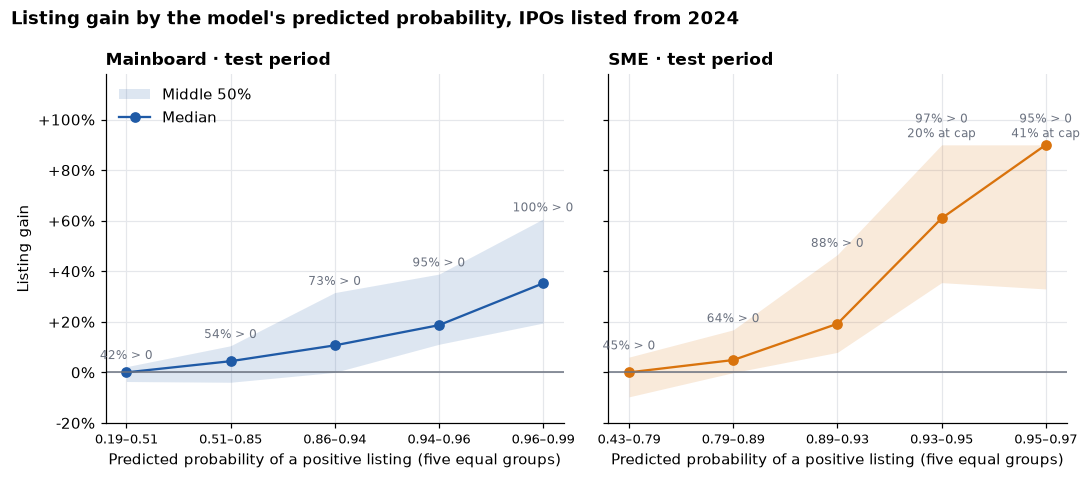

p_min  p_max   n  median_gain    q25    q75  share_positive  \
segment   group                                                                
Mainboard 1      0.190  0.506  38        0.000 -3.615  2.248           0.421   
          2      0.511  0.854  37        4.420 -3.910 10.530           0.541   
          3      0.858  0.937  37       10.680  0.000 31.560           0.730   
          4      0.940  0.956  37       18.670 11.110 38.870           0.946   
          5      0.956  0.987  38       35.230 19.510 60.665           1.000   
SME       1      0.426  0.789  60        0.000 -9.678  6.043           0.450   
          2      0.789  0.886  59        4.880 -0.105 16.825           0.644   
          3      0.889  0.930  59       19.230  7.920 46.590           0.881   
          4      0.930  0.946  59       60.940 35.500 90.000           0.966   
          5      0.947  0.966  59       90.000 32.990 90.000           0.949   

                 at_ceiling  
segment   group              
Mainboard 1           0.000  
          2           0.000  
          3           0.000  
          4           0.000  
          5           0.000  
SME       1           0.017  
          2           0.034  
          3           0.068  
          4           0.203  
          5           0.407

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
quintile_tables = {}
for ax, s in zip(axes, SEGMENTS):
    frame = test[s].assign(p=results[s]['p_model'])
    frame['group'] = pd.qcut(frame['p'].rank(method='first'), 5, labels=[1, 2, 3, 4, 5])
    table = frame.groupby('group', observed=True).agg(
        p_min=('p', 'min'), p_max=('p', 'max'), n=('p', 'size'),
        median_gain=('listing_gain_pct', 'median'), q25=('listing_gain_pct', lambda v: v.quantile(0.25)),
        q75=('listing_gain_pct', lambda v: v.quantile(0.75)),
        share_positive=('listing_gain_pct', lambda v: (v > 0).mean()), at_ceiling=('at_ceiling', 'mean'))
    quintile_tables[SEGMENT_LABELS[s]] = table
    x = np.arange(1, 6)
    ax.fill_between(x, table['q25'], table['q75'], color=SEGMENT_COLORS[s], alpha=0.15, lw=0, label='Middle 50%')
    ax.plot(x, table['median_gain'], 'o-', color=SEGMENT_COLORS[s], label='Median')
    for xi, (_, row) in zip(x, table.iterrows()):
        label = f"{row['share_positive']:.0%} > 0"
        if row['at_ceiling'] >= 0.1:
            label += f"\n{row['at_ceiling']:.0%} at cap"
        ax.annotate(label, (xi, row['q75']), textcoords='offset points', xytext=(0, 5), ha='center',
                    fontsize=8, color=MUTED)
    ax.axhline(0, color=MUTED, lw=1)
    ax.set_xticks(x, [f"{row['p_min']:.2f}–{row['p_max']:.2f}" for _, row in table.iterrows()], fontsize=8.5)
    ax.set_xlabel('Predicted probability of a positive listing (five equal groups)')
    ax.set_title(f'{SEGMENT_LABELS[s]} · test period')
    percent_axis(ax, axis='y')
axes[0].set_ylabel('Listing gain')
axes[0].set_ylim(-20, 118)
axes[0].legend(loc='upper left')
fig.suptitle('Listing gain by the model\'s predicted probability, IPOs listed from 2024',
             x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save_fig(fig, '03_listing_gain_by_predicted_probability')
plt.show()
pd.concat(quintile_tables, names=['segment'])

**Reading.**
- **Applying to every IPO:** median listing gain +10.5% for mainboard (73% positive) and +19.1% for SME (78% positive).
- **Filtering on confidence raises the typical listing gain a lot.**
  - *Mainboard:* the model's p > 0.9 picks half the IPOs (96). Their median gain is +26.7% [+18.4, +33.7] and 95% listed positive. The skipped half's median is 26.7 pp [17.6, 33.3] lower.
  - *SME:* p > 0.9 picks 167 IPOs (56%). Their median is +55.0% [+40.7, +83.3] and 93% listed positive.
- **Subscription alone does about as well.**
  - *Mainboard at p > 0.9:* 91 IPOs, median +26.6%, 95% positive, almost the same result.
  - *SME at p > 0.9:* subscription alone is more selective. It picks 112 IPOs with a median at the +90% cap and 96% positive. Because the two pick different numbers of IPOs, this is not a like-for-like comparison; the AUCs in §2 are.
- **Low thresholds don't filter.** Both forecasts are overconfident, so for SME p > 0.5 keeps 295 or all 296 IPOs.
- **The picks are the IPOs that are hardest to get.**
  - The median retail portion of the model's p > 0.9 picks was oversubscribed 28× (mainboard) and 194× (SME).
  - In IPOs like these most retail applicants are allotted nothing, so the median gain of the picks is far above what an applicant earns per application.
  - For SME, 20–41% of the most confident groups opened at the +90% cap. Their median gain is a real listing price, but a capped one.

## 6 · Verdict

### Answers

**Does the small model beat the baselines?** It beats the naive ones clearly, but not subscription on its own, except slightly for SME.
- **It beats the training base rate and the "> 10×" rule** in both segments. For a positive listing, the Brier score improves on the base rate by 0.02–0.04, and ranking AUC improves on the rule by 0.11–0.12.
- **Mainboard: no better than total subscription alone.** AUC 0.835 vs 0.831 (+0.004 [−0.012, +0.020]), and slightly worse probabilities. Validation on the training years already pointed that way. For mainboard IPOs, the final subscription multiple is the whole signal this data holds about whether the listing will be positive.
- **SME: slightly better than subscription alone.** The model uses NII demand: each doubling multiplies the odds by 1.45 [1.20, 1.76] at the same total and retail demand.
  - *Probabilities:* the Brier score improves by 0.006 [0.001, 0.012].
  - *Ranking:* AUC 0.82 vs 0.80, with an interval that includes zero.
  - The same holds for a gain above 10%. The gain is small and only just clear of zero.

**Does it hold up out of sample?** Ranking does; the probabilities don't.
- Test-period AUCs (0.82–0.89) are close to those on the validation years (0.73–0.91), and higher for SME.
- The model trained on 2016–2023 was too optimistic about 2024–25 IPOs: 78% average forecast vs 73% positive for mainboard, 87% vs 78% for SME.
- The cause is that subscription multiples roughly doubled (mainboard) and rose ten-fold (SME), while a given multiple became less likely to list positive.
- A forecast like this has to be recalibrated on recent listings before its probabilities mean anything.

**Is it useful?** As a ranking, yes: the IPOs the model gave over 90% (about half of each segment) had median listing gains of +27% (mainboard) and +55% (SME), against +11% and +19% for all IPOs. Subscription alone picks just as well.

### What this doesn't show
- **Not a trading strategy.**
  - The model's favourites are the most oversubscribed IPOs (median retail subscription 28× and 194×), where most applicants are allotted nothing.
  - It uses **final** subscription, which is only complete after bidding closes. An applicant decides with partial, earlier-day figures.
  - No costs, no capital tied up across applications, no taxes.
- **Scope.**
  - One test period of two years, with a single change in market conditions. A different period might calibrate differently.
  - Around 190 mainboard and 300 SME test IPOs, so AUC differences of a few hundredths can't be detected.
  - NSE listings only; SME from 2018.
- **Multiple comparisons.** The test period answers a small, pre-set list: the model against three baselines, for two targets and two segments. The SME Brier improvements are just clear of zero (upper bounds −0.001 and −0.000) and would not survive a multiple-comparison adjustment. Treat them as suggestive.